# Лабораторная работа №5
## Предобработка данных для ML и основы аналитики
Годуленко Матвей, ЭТ-213.

Цель: изучить масштабирование, кодирование категорий, ColumnTransformer и построение выборок. Все данные синтетические. Ячейки выполняются сверху вниз. Имена переменных записаны латиницей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    LabelEncoder, OrdinalEncoder, OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True

np.random.seed(42)
n = 800

df = pd.DataFrame({
    'Age':         np.random.randint(18, 76, n),
    'Income':      np.random.lognormal(mean=10.5, sigma=0.9, size=n).round(0),
    'Tenure':      np.random.randint(1, 61, n),
    'CreditScore': np.random.randint(300, 851, n),
    'Gender':      np.random.choice(['M', 'F'], n, p=[0.55, 0.45]),
    'Education':   np.random.choice(
                       ['High School', 'Bachelor', 'Master', 'PhD'],
                       n, p=[0.30, 0.45, 0.20, 0.05]),
    'City':        np.random.choice(
                       ['Moscow', 'SPb', 'Kazan', 'Ufa',
                        'Novosibirsk', 'Ekaterinburg'], n),
})

# Один выброс в доходе для демонстрации
df.loc[0, 'Income'] = 5_000_000

# Целевая переменная зависит от признаков
churn_logit = (
    -0.8
    + 0.04 * (df['Age'] - 45)
    + 1.2 * (df['Tenure'] < 12).astype(int)
)
p_churn = 1 / (1 + np.exp(-churn_logit))
df['Churn'] = np.random.binomial(1, p_churn)

df.to_csv('bank_customers.csv', index=False)

print(df.head())
print(f"Размер: {df.shape}")
print(f"Средний Churn: {df['Churn'].mean():.3f}")
print(df.dtypes)


Matplotlib is building the font cache; this may take a moment.


   Age     Income  Tenure  CreditScore Gender    Education          City  \
0   56  5000000.0      15          369      M       Master           Ufa   
1   69    24836.0      21          510      M       Master  Ekaterinburg   
2   46   133169.0      19          400      M  High School           Ufa   
3   32     6481.0      60          431      F     Bachelor           SPb   
4   60    78179.0      29          680      M     Bachelor           SPb   

   Churn  
0      0  
1      0  
2      0  
3      0  
4      0  
Размер: (800, 8)
Средний Churn: 0.371
Age              int64
Income         float64
Tenure           int64
CreditScore      int64
Gender             str
Education          str
City               str
Churn            int64
dtype: object


Получено 800 строк и 8 столбцов. Первая строка Income = 5 000 000. При исходном генераторе и seed=42 доля Churn составила **0,37125 (37,125%)**. Формулировка «около 0,3» в задании приблизительная; генератор сохранён без подгонки результата.

## 1.1. SMART-цель

In [2]:
smart_goal = 'Снизить 90-дневную долю оттока на 10% относительно контрольной группы среди клиентов со стажем менее 12 месяцев за 3 месяца за счёт персонального предложения и звонка менеджера.'
print(smart_goal)

Снизить 90-дневную долю оттока на 10% относительно контрольной группы среди клиентов со стажем менее 12 месяцев за 3 месяца за счёт персонального предложения и звонка менеджера.


**S:** отток клиентов со стажем менее 12 месяцев, действие — предложение и звонок. **M:** относительное снижение на 10%: например, с 30% до 27%, а не на 10 процентных пунктов. **A:** проверяем достижимость небольшим пилотом в рамках ресурсов банка; по этому датасету достижимость доказать нельзя. **R:** удержание клиентов связано с сохранением клиентской базы. **T:** 3 месяца. Для проверки нужен случайный A/B-тест с одинаковым периодом наблюдения. В исходном Churn период не задан, поэтому исходный CSV не доказывает достижение этой цели.

## 1.2. Декомпозиция и ограничения данных

In [3]:
decomposition_tree = {
    'Клиентская база': {
        'Новые: Tenure <= 12': {'Доля ушедших': 'new_churn_rate'},
        'Существующие: Tenure > 12': {'Доля ушедших': 'existing_churn_rate', 'Стаж ушедших': 'avg_tenure_of_churned'}
    },
    'Доход клиента (не выручка банка)': {'Уровень дохода': {'Среднее': 'avg_income_per_client', 'Медиана': 'median_income'}},
    'Доход банка: на клиента и частота операций — нужны данные': {},
    'Качество: обращения и скорость ответа — нужны данные': {}
}
def print_tree(tree, level=0):
    for key, value in tree.items():
        print('  ' * level + key)
        if isinstance(value, dict):
            if value:
                print_tree(value, level + 1)
            else:
                print('  ' * (level + 1) + 'Нет измеримых листьев в текущем CSV')
        else:
            print('  ' * (level + 1) + value)
print_tree(decomposition_tree)
metrics = {
    'new_churn_rate': df.loc[df['Tenure'] <= 12, 'Churn'].mean(),
    'existing_churn_rate': df.loc[df['Tenure'] > 12, 'Churn'].mean(),
    'avg_tenure_of_churned': df.loc[df['Churn'] == 1, 'Tenure'].mean(),
    'avg_income_per_client': df['Income'].mean(),
    'median_income': df['Income'].median()
}
print(pd.Series(metrics).round(3))

Клиентская база
  Новые: Tenure <= 12
    Доля ушедших
      new_churn_rate
  Существующие: Tenure > 12
    Доля ушедших
      existing_churn_rate
    Стаж ушедших
      avg_tenure_of_churned
Доход клиента (не выручка банка)
  Уровень дохода
    Среднее
      avg_income_per_client
    Медиана
      median_income
Доход банка: на клиента и частота операций — нужны данные
  Нет измеримых листьев в текущем CSV
Качество: обращения и скорость ответа — нужны данные
  Нет измеримых листьев в текущем CSV
new_churn_rate               0.531
existing_churn_rate          0.331
avg_tenure_of_churned       27.306
avg_income_per_client    67728.274
median_income            38086.000
dtype: float64


Сегменты Tenure ≤ 12 и > 12 не пересекаются и покрывают выборку; граница 12 месяцев — наше рабочее определение нового клиента. Причинные ветви в целом **не являются строго MECE**: качество сервиса влияет и на отток, и на доход. Дерево неполно: нет тарифов, конкурентов, причин закрытия счёта. Условие требует ветви про доход банка и поддержку, но в CSV нет операций, комиссий, обращений и времени ответа. Поэтому эти ветви оставлены без выдуманных измеримых листьев. Нужно запросить банковскую выручку по клиенту, операции с датами, обращения и время ответа. Income — личный доход клиента, его нельзя выдавать за выручку банка. Churn=0 — отсутствие отмеченного оттока, но не доказательство активности по операциям.

## 1.3. Смещения выборки

In [4]:
biases = {
    1: ('survivorship', 'Рассмотрены только успешные стартапы; провалившиеся исключены.'),
    2: ('response', 'Чаще отвечают мотивированные пользователи, например очень довольные или недовольные.'),
    3: ('selection', 'Клиенты из Google-рекламы могут отличаться от остальных клиентов банка.'),
    4: ('recall', 'Люди неточно вспоминают число посещений за целый год.')
}
for num, (bias, reason) in biases.items():
    print(num, bias, '—', reason)

1 survivorship — Рассмотрены только успешные стартапы; провалившиеся исключены.
2 response — Чаще отвечают мотивированные пользователи, например очень довольные или недовольные.
3 selection — Клиенты из Google-рекламы могут отличаться от остальных клиентов банка.
4 recall — Люди неточно вспоминают число посещений за целый год.


В сценарии 2 дополнительно есть selection bias: сайт не охватывает клиентов, которые им не пользуются. Основной ответ response связан с добровольным участием в опросе.

## 2.1. Типы признаков

In [5]:
numeric_cols = ['Age', 'Income', 'Tenure', 'CreditScore']
nominal_cols = ['Gender', 'City']
ordinal_cols = ['Education']
original_cols = set(df.columns) - {'Churn'}
covered = set(numeric_cols) | set(nominal_cols) | set(ordinal_cols)
assert original_cols == covered
print('Все признаки распределены по типам')

Все признаки распределены по типам


Education имеет принятый порядок High School < Bachelor < Master < PhD. Расстояния между уровнями не обязаны быть одинаковыми. City — название города, у городов нет естественного отношения «больше — меньше». Churn — целевая переменная, не входной признак.

## 2.2. Выбросы

In [6]:
display(df[numeric_cols].describe().round(1))
z_scores = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()
print('Выбросы по правилу |z| > 3:')
print((z_scores.abs() > 3).sum())
print('Первая строка Income:', df.loc[0, 'Income'])

,Age,Income,Tenure,CreditScore
count,800.0,800.0,800.0,800.0
mean,47.1,67728.3,29.5,578.8
std,16.6,188315.9,17.0,159.4
min,18.0,2963.0,1.0,300.0
25%,33.0,20203.5,15.0,440.0
50%,47.5,38086.0,29.0,576.0
75%,61.0,75490.2,44.0,720.0
max,75.0,5000000.0,60.0,850.0


Выбросы по правилу |z| > 3:
Age            0
Income         1
Tenure         0
CreditScore    0
dtype: int64
Первая строка Income: 5000000.0


В Income специально добавлено 5 000 000. Выбираю RobustScaler: медиана и межквартильный размах устойчивее среднего и стандартного отклонения. Правило трёх сигм — ориентир, а не доказательство ошибки; логнормальное распределение само имеет длинный хвост, а сильный выброс искажает среднее и СКО.

## 3.1. Сравнение скейлеров

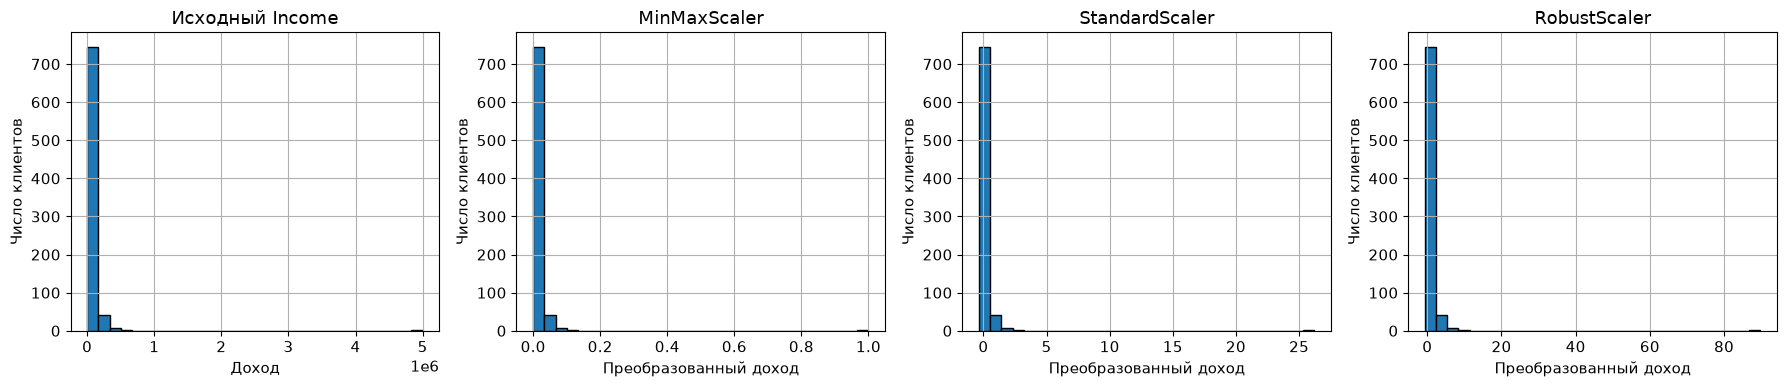

In [7]:
income = df[['Income']]
scaled_income = {
    'Исходный Income': income.to_numpy().ravel(),
    'MinMaxScaler': MinMaxScaler().fit_transform(income).ravel(),
    'StandardScaler': StandardScaler().fit_transform(income).ravel(),
    'RobustScaler': RobustScaler().fit_transform(income).ravel()
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, values) in zip(axes, scaled_income.items()):
    ax.hist(values, bins=30, edgecolor='black')
    ax.set_title(name)
    ax.set_xlabel('Доход' if name == 'Исходный Income' else 'Преобразованный доход')
    ax.set_ylabel('Число клиентов')
plt.tight_layout()
plt.show()

Все три скейлера — линейные преобразования одного столбца: **форма распределения сохраняется у всех**, нормальным оно не становится. Меняются только начало отсчёта и масштаб. MinMax особенно чувствителен к экстремальному максимуму: основная масса значений сжимается к нулю. StandardScaler тоже чувствителен через среднее и СКО. Для Income выбираю RobustScaler; он не удаляет выброс и не устраняет асимметрию, но устойчиво оценивает масштаб основной массы. Здесь fit на всей выборке используется только для демонстрации, в ML ниже fit выполняется только на train.

## 3.2. Скейлер для каждого признака

In [8]:
scaler_choice = {'Age': 'StandardScaler', 'Income': 'RobustScaler', 'Tenure': 'MinMaxScaler', 'CreditScore': 'StandardScaler'}
justification = {
    'Age': 'Центрирование и единичный масштаб; экстремальных выбросов нет.',
    'Income': 'Выброс и длинный правый хвост; устойчивый масштаб на основе IQR.',
    'Tenure': 'Ограниченный диапазон 1–60 месяцев; удобно отобразить его в [0, 1].',
    'CreditScore': 'Приведение к сопоставимому масштабу для чувствительных к масштабу моделей.'
}
for col in numeric_cols:
    print(col, '—', scaler_choice[col], ':', justification[col])

Age — StandardScaler : Центрирование и единичный масштаб; экстремальных выбросов нет.
Income — RobustScaler : Выброс и длинный правый хвост; устойчивый масштаб на основе IQR.
Tenure — MinMaxScaler : Ограниченный диапазон 1–60 месяцев; удобно отобразить его в [0, 1].
CreditScore — StandardScaler : Приведение к сопоставимому масштабу для чувствительных к масштабу моделей.


Выбор согласован с ColumnTransformer из задания 5.1. StandardScaler не требует нормального распределения входного признака и не делает его нормальным. Для деревьев масштабирование обычно не требуется.

## 4.1. Кодирование Gender

In [9]:
le = LabelEncoder()
df['Gender_Label'] = le.fit_transform(df['Gender'])
df_ohe = pd.get_dummies(df['Gender'], prefix='Gender', dtype=int)
print(dict(zip(le.classes_, le.transform(le.classes_))))
display(pd.concat([df[['Gender', 'Gender_Label']], df_ohe], axis=1).head())

{'F': np.int64(0), 'M': np.int64(1)}


,Gender,Gender_Label,Gender_F,Gender_M
0,M,1,0,1
1,M,1,0,1
2,M,1,0,1
3,F,0,1,0
4,M,1,0,1


Для бинарного Gender код 0/1 допустим и для линейных моделей, и для деревьев: это один индикатор, ложного порядка из трёх и более категорий не возникает. Для номинальных признаков с ≥3 категориями числовые метки вводят искусственный порядок и расстояния, особенно мешая линейным моделям, kNN и SVM. Даже дереву пороговое разбиение по произвольным кодам ограничивает варианты группировки. LabelEncoder обычно предназначен для целевой переменной; здесь он показан по условию.

## 4.2. Порядок Education

In [10]:
edu_order = ['High School', 'Bachelor', 'Master', 'PhD']
oe = OrdinalEncoder(categories=[edu_order])
df['Education_Ord'] = oe.fit_transform(df[['Education']])
display(df[['Education', 'Education_Ord']].drop_duplicates().sort_values('Education_Ord'))
auto = OrdinalEncoder().fit(df[['Education']])
print('Автоматический порядок:', auto.categories_[0])

,Education,Education_Ord
2,High School,0.0
3,Bachelor,1.0
0,Master,2.0
19,PhD,3.0


Автоматический порядок: ['Bachelor' 'High School' 'Master' 'PhD']


Без categories строки получают алфавитный порядок: Bachelor=0, High School=1, Master=2, PhD=3. Первые два уровня перепутаны относительно заданного смысла. Явный порядок даёт High School=0, Bachelor=1, Master=2, PhD=3. Порядок корректен, но одинаковые числовые интервалы между ступенями — дополнительное допущение для линейной модели.

## 4.3. Частота City

In [11]:
freq_map = df['City'].value_counts()
df['City_Freq'] = df['City'].map(freq_map)
display(df[['City', 'City_Freq']].drop_duplicates().sort_values('City_Freq'))

,City,City_Freq
0,Ufa,115
16,Kazan,133
7,Moscow,135
1,Ekaterinburg,138
5,Novosibirsk,139
3,SPb,140


Использованы абсолютные частоты по условию. Разные города с одинаковой частотой получают одинаковый код: теряется их идентичность. Это критично, если отток зависит от конкретного города при одинаковой популярности городов. Частоты также зависят от объёма и состава выборки. В реальном ML карту считают на train, неизвестному городу задают резервное значение. Ниже демонстрационный City_Freq исключён из X.

## 5.1. ColumnTransformer без утечки

In [12]:
X = df.drop(columns=['Churn', 'Gender_Label', 'Education_Ord', 'City_Freq'], errors='ignore')
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
preprocessor = ColumnTransformer(transformers=[
    ('standard', StandardScaler(), ['Age', 'CreditScore']),
    ('robust', RobustScaler(), ['Income']),
    ('minmax', MinMaxScaler(), ['Tenure']),
    ('nominal', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['Gender', 'City']),
    ('ordinal', OrdinalEncoder(categories=[edu_order]), ['Education'])
])
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
print(X_train.shape, '->', X_train_prepared.shape)
print(X_test.shape, '->', X_test_prepared.shape)
print(preprocessor.get_feature_names_out())

(600, 7) -> (600, 11)
(200, 7) -> (200, 11)
['standard__Age' 'standard__CreditScore' 'robust__Income' 'minmax__Tenure'
 'nominal__Gender_M' 'nominal__City_Kazan' 'nominal__City_Moscow'
 'nominal__City_Novosibirsk' 'nominal__City_SPb' 'nominal__City_Ufa'
 'ordinal__Education']


1. fit оценивает средние, масштабы и категории только по train. Test получает уже зафиксированное преобразование. Иначе информация из теста попадёт в обучение. Демонстрационные колонки из части 4 удалены; Churn также исключён.
2. Gender даёт 1 столбец, City — 5, если на train присутствуют все 2 пола и 6 городов. Числовые признаки дают 4, Education — 1, всего 11.
3. По умолчанию OneHotEncoder(handle_unknown='error') выдаст ошибку на новом городе. Здесь задано ignore: все индикаторы нового города будут нулевыми. При drop='first' такой код неотличим от базовой категории — это ограничение. Альтернатива — обучать отдельную категорию Unknown или применять infrequent_if_exist с настройкой редких категорий. Для неизвестного Education по умолчанию будет ошибка; это нужно отдельно продумать при внедрении.

## 6.1. Случайная и стратифицированная выборки

In [13]:
def stratified_sample(df, strat_col, n_total, random_state=42):
    if n_total < 0 or n_total > len(df):
        raise ValueError('Неверный размер выборки')
    counts = df[strat_col].value_counts(dropna=False)
    expected = counts / len(df) * n_total
    quotas = np.floor(expected).astype(int)
    remainder = n_total - quotas.sum()
    order = (expected - quotas).sort_values(ascending=False).index
    for group in order[:remainder]:
        quotas.loc[group] += 1
    parts = []
    for group, size in quotas.items():
        mask = df[strat_col].isna() if pd.isna(group) else df[strat_col].eq(group)
        parts.append(df.loc[mask].sample(n=int(size), random_state=random_state))
    return pd.concat(parts).sample(frac=1, random_state=random_state)
s_rand = df.sample(n=100, random_state=42)
s_strat = stratified_sample(df, 'Churn', n_total=100)
print(f"Популяция: {df['Churn'].mean():.3f}")
print(f"Случайная: {s_rand['Churn'].mean():.3f}")
print(f"Стратифицированная: {s_strat['Churn'].mean():.3f}")
print('Размер стратифицированной:', len(s_strat))
errors = {'Случайная': abs(s_rand['Churn'].mean() - df['Churn'].mean()),
          'Стратифицированная': abs(s_strat['Churn'].mean() - df['Churn'].mean())}
print('Ближе к популяции:', min(errors, key=errors.get))

Популяция: 0.371
Случайная: 0.320
Стратифицированная: 0.370
Размер стратифицированной: 100
Ближе к популяции: Стратифицированная


Целые квоты получены методом наибольших остатков, поэтому суммарно ровно 100 строк. Стратифицированная выборка сохраняет долю Churn с точностью округления; простая случайная может случайно оказаться ближе, но не контролирует пропорции. Сохранение доли Churn не гарантирует репрезентативности по всем остальным признакам. Churn можно применять для разбиения, но нельзя оставлять в X: это готовый ответ, который неизвестен при прогнозе.

В расчёте: популяция 0,37125; случайная выборка 0,32; стратифицированная 0,37. Стратифицированная ближе к популяции.

## 6.2. Размер выборки и оценка медианы

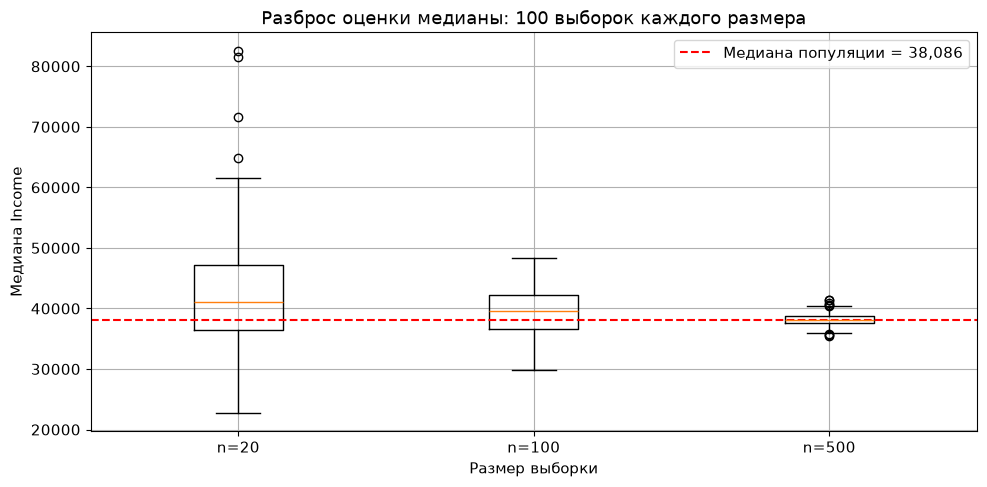

n=20: std = 10,391
n=100: std = 3,887
n=500: std = 1,138


In [14]:
sizes = [20, 100, 500]
results = {n: [] for n in sizes}
for n in sizes:
    for seed in range(100):
        results[n].append(df.sample(n=n, random_state=seed)['Income'].median())
fig, ax = plt.subplots()
ax.boxplot([results[n] for n in sizes], tick_labels=[f'n={n}' for n in sizes])
ax.axhline(df['Income'].median(), color='red', linestyle='--', label=f"Медиана популяции = {df['Income'].median():,.0f}")
ax.set_title('Разброс оценки медианы: 100 выборок каждого размера')
ax.set_xlabel('Размер выборки')
ax.set_ylabel('Медиана Income')
ax.legend()
plt.tight_layout()
plt.show()
for n in sizes:
    print(f'n={n}: std = {np.std(results[n]):,.0f}')

При увеличении n разброс оценки медианы уменьшается. Общая тенденция согласуется с порядком 1/√n, но σ/√n — стандартная ошибка **среднего** при независимых наблюдениях, а не точная формула для медианы. Для медианы важна плотность распределения около медианы. Выборки здесь без возвращения из 800 строк; при n=500 заметна дополнительная поправка на конечную совокупность. Среднее сильнее реагировало бы на попадание выброса 5 000 000, особенно при малых n; медиана устойчивее.

Полученные СКО медиан: n=20 — 10 391; n=100 — 3 887; n=500 — 1 138. Уменьшение разброса видно и на графике.

## Общий вывод

Предобработка зависит от смысла и распределения признака. Для Income выбран RobustScaler, для номинальных признаков — One-Hot, для образования — явный порядковый код. ColumnTransformer обучен только на train и формирует 11 признаков. Стратификация контролирует долю целевого класса, а увеличение выборки уменьшает разброс оценки медианы. Датасет не содержит данных о поддержке и выручке банка, поэтому причинные и бизнес-выводы ограничены.